# Brain Tumor MRI Image Classification

## Machine Learning Project

This project develops a deep-learning system for classifying brain MRI images into four categories:

1. Glioma
2. Meningioma
3. No Tumor
4. Pituitary

Three deep-learning approaches are evaluated:

- Custom Convolutional Neural Network (CNN)
- MobileNetV2 Transfer Learning
- EfficientNet Transfer Learning

The final application uses the best-performing trained model and provides explainability using Gradient-weighted Class Activation Mapping (Grad-CAM).

### Project Pipeline

MRI Dataset → Data Preprocessing → Data Augmentation → Model Training → Model Evaluation → Model Comparison → Best Model Selection → Grad-CAM Explainability → Streamlit Application

> **Research-use disclaimer:** This project is an academic machine-learning prototype and is not intended for medical diagnosis or treatment decisions.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from PIL import Image

print("TensorFlow version:", tf.__version__)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

TensorFlow version: 2.21.0
NumPy version: 2.5.3
Pandas version: 3.0.6


In [2]:
# The notebook is stored inside:
# BRAIN-TUMOR-MRI-CLASSIFICATION/notebooks/

PROJECT_ROOT = Path.cwd().parent

DATASET_DIR = PROJECT_ROOT / "dataset"
TRAIN_DIR = DATASET_DIR / "train"
VALID_DIR = DATASET_DIR / "valid"
TEST_DIR = DATASET_DIR / "test"

MODELS_DIR = PROJECT_ROOT / "models"
RESULTS_DIR = PROJECT_ROOT / "results"

print("Project root :", PROJECT_ROOT)
print("Dataset      :", DATASET_DIR)
print("Models       :", MODELS_DIR)
print("Results      :", RESULTS_DIR)

assert TRAIN_DIR.exists(), f"Train directory not found: {TRAIN_DIR}"
assert VALID_DIR.exists(), f"Validation directory not found: {VALID_DIR}"
assert TEST_DIR.exists(), f"Test directory not found: {TEST_DIR}"

print("\n✓ Project directories found successfully.")

Project root : /Users/malaypal/BRAIN-TUMOR-MRI-CLASSIFICATION
Dataset      : /Users/malaypal/BRAIN-TUMOR-MRI-CLASSIFICATION/dataset
Models       : /Users/malaypal/BRAIN-TUMOR-MRI-CLASSIFICATION/models
Results      : /Users/malaypal/BRAIN-TUMOR-MRI-CLASSIFICATION/results

✓ Project directories found successfully.


In [3]:
CLASS_NAMES = sorted([
    folder.name
    for folder in TRAIN_DIR.iterdir()
    if folder.is_dir()
])

print("Detected classes:")
for index, class_name in enumerate(CLASS_NAMES):
    print(f"{index}: {class_name}")

print("\nNumber of classes:", len(CLASS_NAMES))

Detected classes:
0: glioma
1: meningioma
2: no_tumor
3: pituitary

Number of classes: 4


In [4]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png"}

def count_images(directory):
    counts = {}

    for class_name in CLASS_NAMES:
        class_dir = directory / class_name

        counts[class_name] = sum(
            1
            for file in class_dir.rglob("*")
            if file.is_file() and file.suffix.lower() in IMAGE_EXTENSIONS
        )

    return counts


train_counts = count_images(TRAIN_DIR)
valid_counts = count_images(VALID_DIR)
test_counts = count_images(TEST_DIR)

distribution_df = pd.DataFrame({
    "Class": CLASS_NAMES,
    "Train": [train_counts[c] for c in CLASS_NAMES],
    "Validation": [valid_counts[c] for c in CLASS_NAMES],
    "Test": [test_counts[c] for c in CLASS_NAMES]
})

distribution_df["Total"] = (
    distribution_df["Train"]
    + distribution_df["Validation"]
    + distribution_df["Test"]
)

distribution_df

,Class,Train,Validation,Test,Total
0,glioma,564,161,80,805
1,meningioma,358,124,63,545
2,no_tumor,335,99,49,483
3,pituitary,438,118,54,610


In [5]:
print("Training images   :", distribution_df["Train"].sum())
print("Validation images :", distribution_df["Validation"].sum())
print("Testing images    :", distribution_df["Test"].sum())
print("Total images      :", distribution_df["Total"].sum())

Training images   : 1695
Validation images : 502
Testing images    : 246
Total images      : 2443


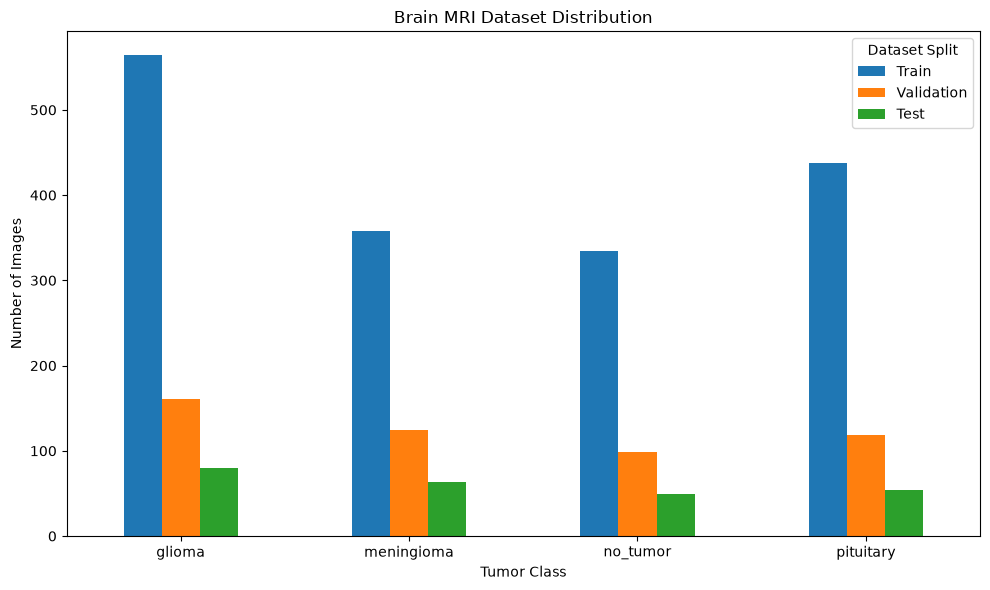

In [6]:
plot_df = distribution_df.set_index("Class")[["Train", "Validation", "Test"]]

ax = plot_df.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Brain MRI Dataset Distribution")
plt.xlabel("Tumor Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)
plt.legend(title="Dataset Split")
plt.tight_layout()
plt.show()

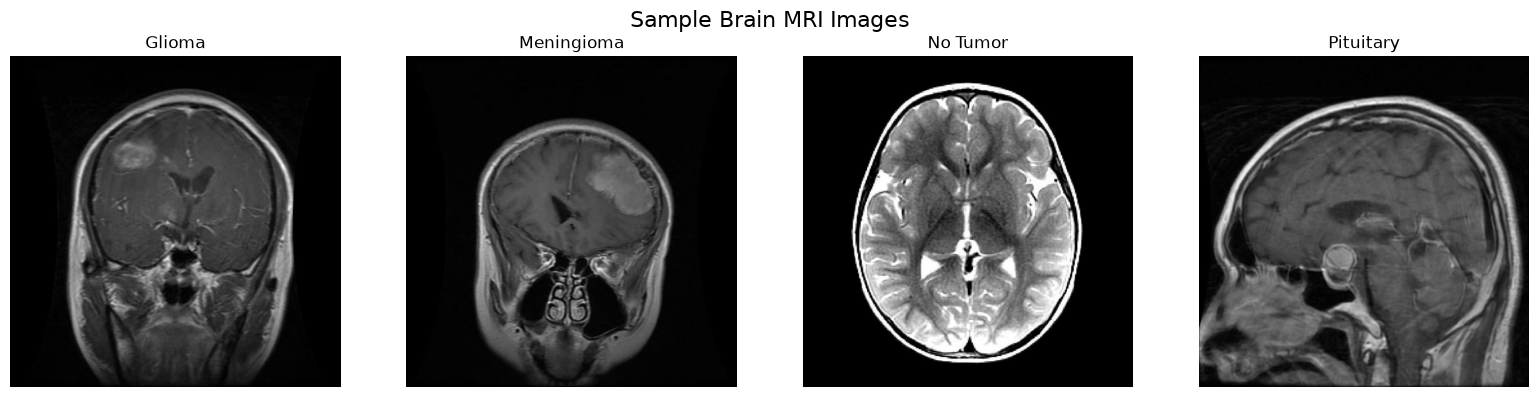

In [7]:
fig, axes = plt.subplots(1, len(CLASS_NAMES), figsize=(16, 4))

for ax, class_name in zip(axes, CLASS_NAMES):
    class_dir = TRAIN_DIR / class_name

    images = [
        file for file in class_dir.iterdir()
        if file.is_file() and file.suffix.lower() in IMAGE_EXTENSIONS
    ]

    if images:
        image = Image.open(images[0]).convert("RGB")

        ax.imshow(image)
        ax.set_title(class_name.replace("_", " ").title())
        ax.axis("off")

plt.suptitle("Sample Brain MRI Images", fontsize=16)
plt.tight_layout()
plt.show()

## Image Preprocessing

All MRI images are converted to RGB format and resized to **224 × 224 pixels** to match the input resolution of the neural-network architectures.

The training pipeline uses categorical labels for the four-class classification problem.

Data augmentation is applied to the training data to improve generalization. The implemented augmentation includes:

- Random horizontal flipping
- Small random rotations
- Random zoom
- Random translation
- Random contrast adjustment

The validation and test datasets are not randomly augmented.

The TensorFlow data pipeline also uses prefetching with `tf.data.AUTOTUNE` to improve input-pipeline efficiency.

In [8]:
result_files = sorted([
    file.name
    for file in RESULTS_DIR.glob("*")
    if file.is_file()
])

print("Available result files:\n")

for file in result_files:
    print("•", file)

Available result files:

• custom_cnn_history.json
• custom_cnn_test_metrics.json
• efficientnet_history.json
• efficientnet_test_metrics.json
• mobilenet_history.json
• mobilenet_test_metrics.json
• model_comparison.json
• model_comparison_report.txt


In [9]:
def load_json(filename):
    path = RESULTS_DIR / filename

    if not path.exists():
        print(f"Not found: {filename}")
        return None

    with open(path, "r") as file:
        return json.load(file)


custom_metrics = load_json("custom_cnn_test_metrics.json")
mobilenet_metrics = load_json("mobilenet_test_metrics.json")
efficientnet_metrics = load_json("efficientnet_test_metrics.json")

print("Custom CNN:")
print(custom_metrics)

print("\nMobileNetV2:")
print(mobilenet_metrics)

print("\nEfficientNet:")
print(efficientnet_metrics)

Custom CNN:
{'model': 'Custom CNN', 'test_loss': 1.4280331134796143, 'accuracy': 0.5040650406504065, 'precision_weighted': 0.40976957927141044, 'recall_weighted': 0.5040650406504065, 'f1_weighted': 0.4498666854777588}

MobileNetV2:
{'test_loss': 0.45080292224884033, 'accuracy': 0.8495934959349594, 'precision': 0.8596574124533672, 'recall': 0.8495934959349594, 'f1_score': 0.8483819617366799}

EfficientNet:
{'model': 'EfficientNetB0', 'test_images': 246, 'test_loss': 0.4168336093425751, 'accuracy': 0.8373983739837398, 'precision': 0.8462319594126174, 'recall': 0.8373983739837398, 'f1_score': 0.8361900775772286, 'accuracy_percent': 83.73983739837398, 'precision_percent': 84.62319594126174, 'recall_percent': 83.73983739837398, 'f1_score_percent': 83.61900775772287}


In [10]:
comparison_path = RESULTS_DIR / "model_comparison.json"

if comparison_path.exists():
    with open(comparison_path, "r") as file:
        model_comparison = json.load(file)

    print("Saved model comparison:")
    print(json.dumps(model_comparison, indent=4))
else:
    print("model_comparison.json was not found.")

Saved model comparison:
{
    "models": {
        "Custom CNN": {
            "accuracy": 50.40650406504065,
            "precision": 40.976957927141044,
            "recall": 50.40650406504065,
            "f1_score": 44.986668547775885
        },
        "MobileNetV2": {
            "accuracy": 84.95934959349594,
            "precision": 85.96574124533673,
            "recall": 84.95934959349594,
            "f1_score": 84.838196173668
        },
        "EfficientNetB0": {
            "accuracy": 83.73983739837398,
            "precision": 84.62319594126174,
            "recall": 83.73983739837398,
            "f1_score": 83.61900775772287
        }
    },
    "best_model": "MobileNetV2",
    "best_test_accuracy": 84.95934959349594
}


In [20]:
comparison_df = pd.DataFrame({
    "Model": ["Custom CNN", "MobileNetV2", "EfficientNetB0"],
    "Accuracy": [50.4065, 84.9593, 83.7398],
    "Precision": [40.9770, 85.9657, 84.6232],
    "Recall": [50.4065, 84.9593, 83.7398],
    "F1 Score": [44.9867, 84.8382, 83.6190]
})

comparison_df

,Model,Accuracy,Precision,Recall,F1 Score
0,Custom CNN,50.4065,40.9770,50.4065,44.9867
1,MobileNetV2,84.9593,85.9657,84.9593,84.8382
2,EfficientNetB0,83.7398,84.6232,83.7398,83.6190


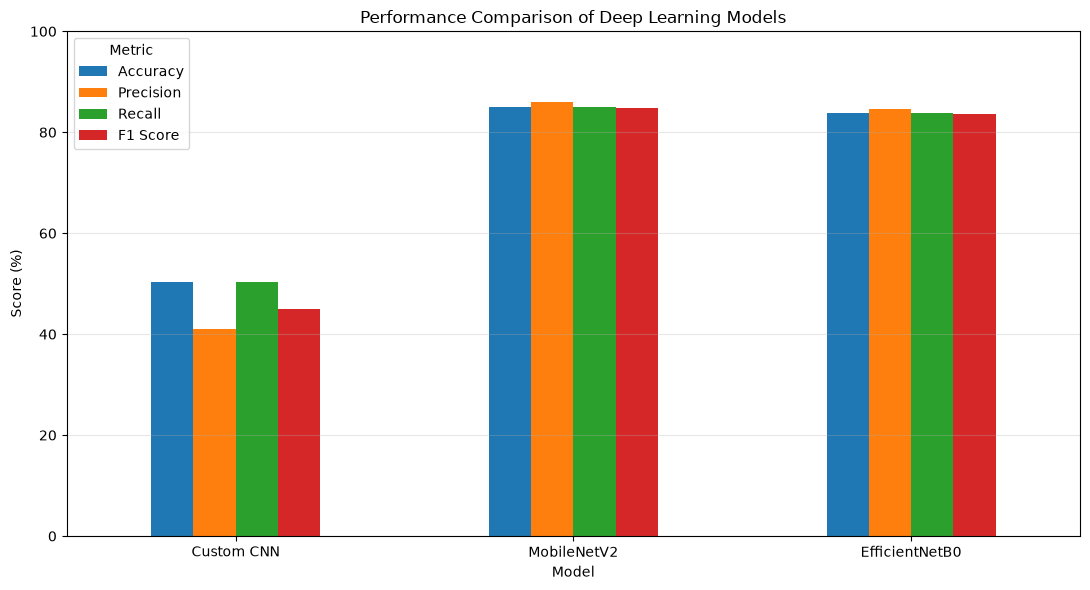

In [21]:
ax = comparison_df.set_index("Model").plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Performance Comparison of Deep Learning Models")
plt.xlabel("Model")
plt.ylabel("Score (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.legend(title="Metric")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [11]:
history_files = {
    "Custom CNN": "custom_cnn_history.json",
    "MobileNetV2": "mobilenet_history.json",
    "EfficientNet": "efficientnet_history.json",
}

histories = {}

for model_name, filename in history_files.items():
    path = RESULTS_DIR / filename

    if path.exists():
        with open(path, "r") as file:
            histories[model_name] = json.load(file)

print("Loaded histories:", list(histories.keys()))

Loaded histories: ['Custom CNN', 'MobileNetV2', 'EfficientNet']


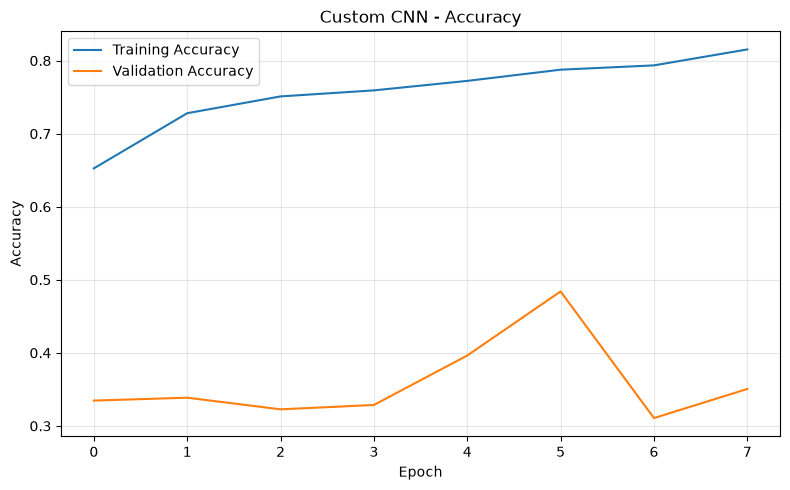

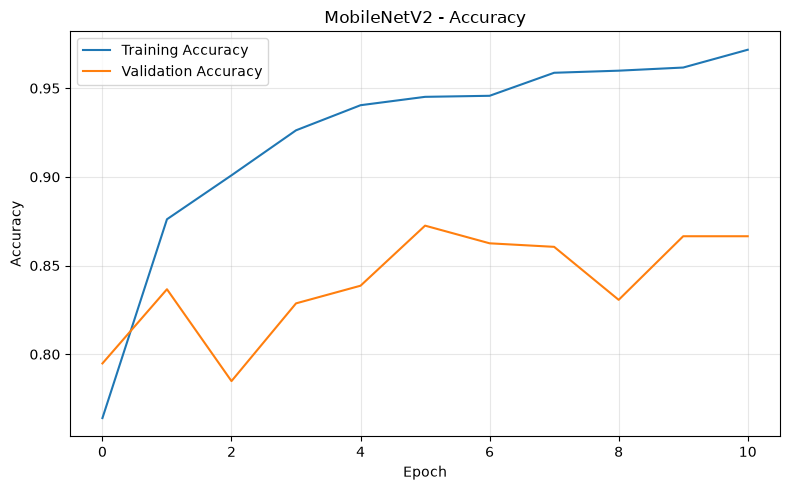

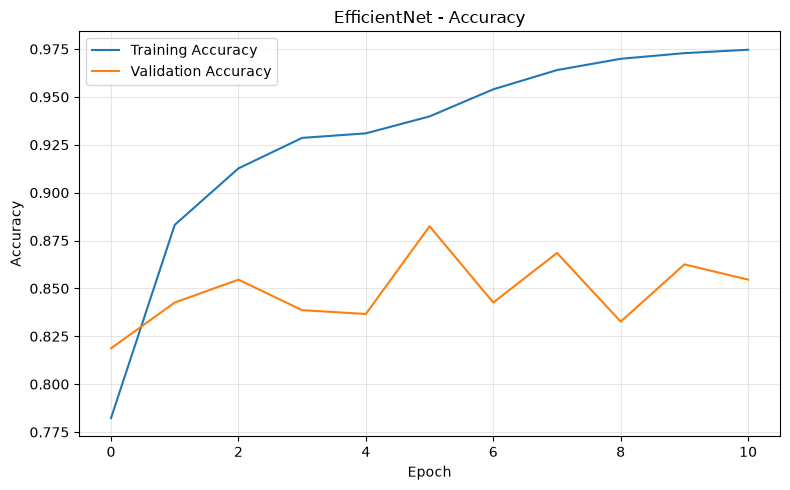

In [12]:
for model_name, history in histories.items():
    
    if "accuracy" in history and "val_accuracy" in history:

        plt.figure(figsize=(8, 5))

        plt.plot(history["accuracy"], label="Training Accuracy")
        plt.plot(history["val_accuracy"], label="Validation Accuracy")

        plt.title(f"{model_name} - Accuracy")
        plt.xlabel("Epoch")
        plt.ylabel("Accuracy")
        plt.legend()
        plt.grid(alpha=0.3)
        plt.tight_layout()
        plt.show()

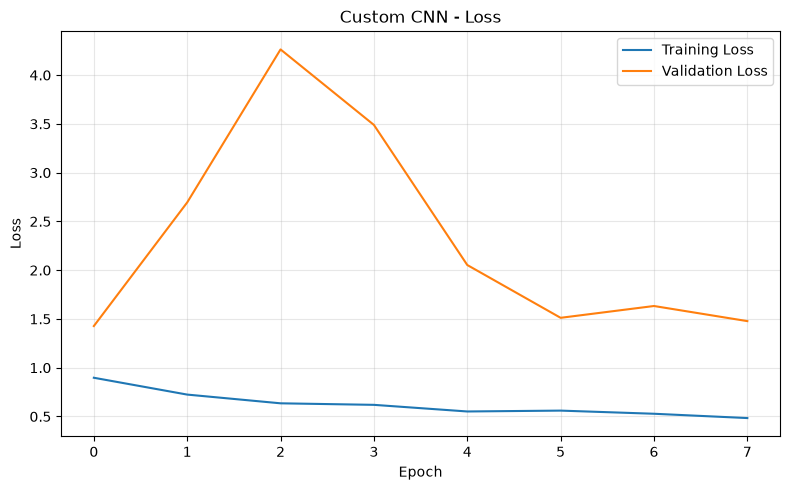

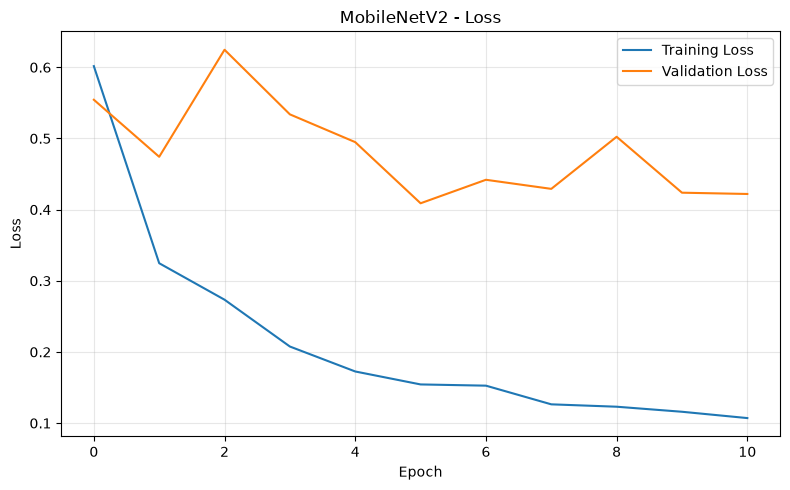

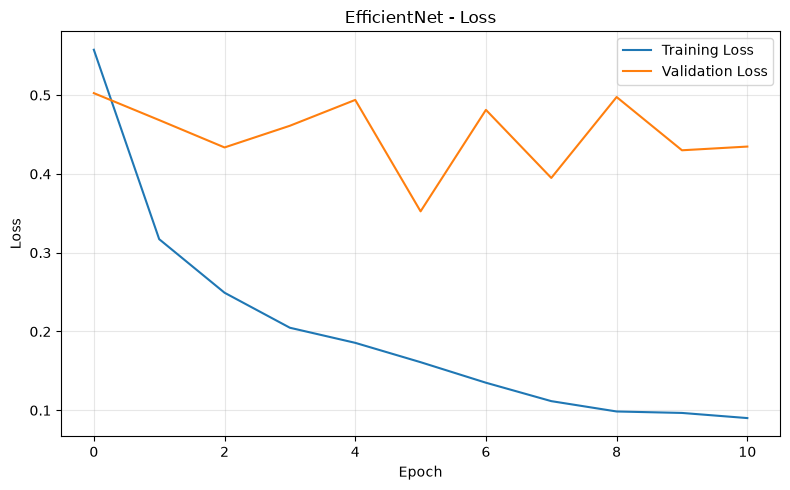

In [13]:
for model_name, history in histories.items():
    
    if "loss" in history and "val_loss" in history:

        plt.figure(figsize=(8, 5))

        plt.plot(history["loss"], label="Training Loss")
        plt.plot(history["val_loss"], label="Validation Loss")

        plt.title(f"{model_name} - Loss")
        plt.xlabel("Epoch")
        plt.ylabel("Loss")
        plt.legend()
        plt.grid(alpha=0.3)
        plt.tight_layout()
        plt.show()

Confusion matrices found:
• custom_cnn_confusion_matrix.png


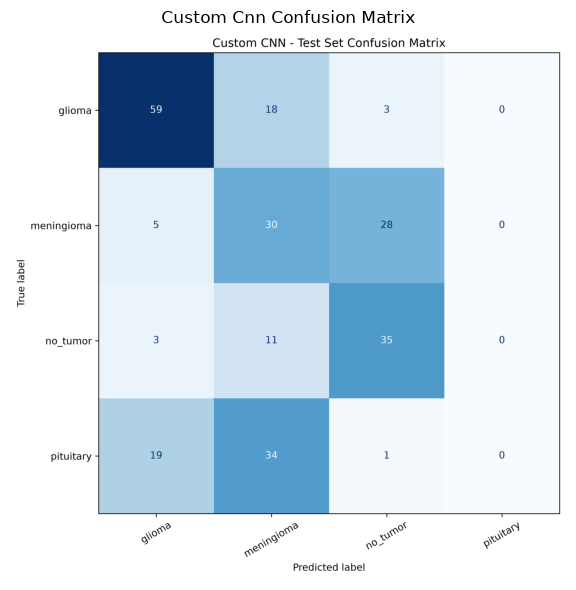

• efficientnet_confusion_matrix.png


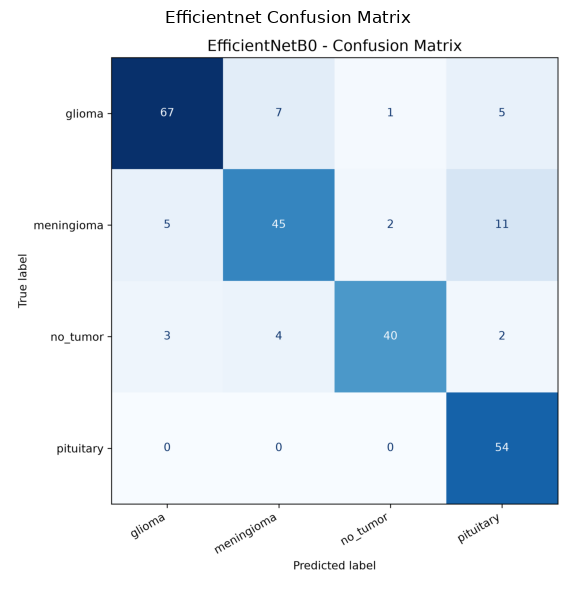

• mobilenet_confusion_matrix.png


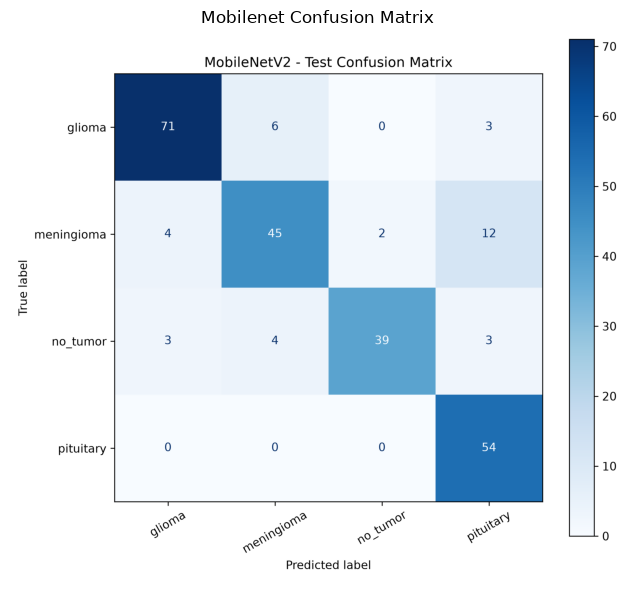

In [14]:
CONFUSION_DIR = RESULTS_DIR / "confusion_matrices"

if CONFUSION_DIR.exists():

    confusion_files = sorted([
        file
        for file in CONFUSION_DIR.iterdir()
        if file.suffix.lower() in IMAGE_EXTENSIONS
    ])

    print("Confusion matrices found:")

    for file in confusion_files:
        print("•", file.name)

        image = Image.open(file)

        plt.figure(figsize=(7, 6))
        plt.imshow(image)
        plt.axis("off")
        plt.title(file.stem.replace("_", " ").title())
        plt.tight_layout()
        plt.show()

else:
    print("Confusion matrix directory not found.")

In [15]:
REPORT_DIR = RESULTS_DIR / "classification_reports"

if REPORT_DIR.exists():

    report_files = sorted([
        file
        for file in REPORT_DIR.iterdir()
        if file.is_file()
    ])

    for file in report_files:

        print("\n" + "=" * 70)
        print(file.name)
        print("=" * 70)

        try:
            print(file.read_text())
        except UnicodeDecodeError:
            print("This report is not stored as plain text.")

else:
    print("Classification report directory not found.")


custom_cnn_classification_report.json
{
    "glioma": {
        "precision": 0.686046511627907,
        "recall": 0.7375,
        "f1-score": 0.7108433734939759,
        "support": 80.0
    },
    "meningioma": {
        "precision": 0.3225806451612903,
        "recall": 0.47619047619047616,
        "f1-score": 0.38461538461538464,
        "support": 63.0
    },
    "no_tumor": {
        "precision": 0.5223880597014925,
        "recall": 0.7142857142857143,
        "f1-score": 0.603448275862069,
        "support": 49.0
    },
    "pituitary": {
        "precision": 0.0,
        "recall": 0.0,
        "f1-score": 0.0,
        "support": 54.0
    },
    "accuracy": 0.5040650406504065,
    "macro avg": {
        "precision": 0.38275380412267246,
        "recall": 0.4819940476190476,
        "f1-score": 0.42472675849285735,
        "support": 246.0
    },
    "weighted avg": {
        "precision": 0.40976957927141044,
        "recall": 0.5040650406504065,
        "f1-score": 0.44986668547

## Models Evaluated

### 1. Custom CNN

A custom convolutional neural network was developed as a baseline model. The CNN learns image features directly from the brain MRI training dataset.

### 2. MobileNetV2

MobileNetV2 was used as a transfer-learning architecture with pretrained ImageNet weights. The convolutional feature extractor was initially frozen and a new classification head was added for the four brain MRI classes.

The classification head includes global average pooling, dropout, a dense layer and a four-unit Softmax output layer.

### 3. EfficientNet

EfficientNet was also evaluated using transfer learning. It provides an alternative pretrained convolutional architecture for comparing classification performance against the Custom CNN and MobileNetV2 models.

### Transfer Learning

Transfer learning allows representations learned from a large image dataset to be reused for the MRI classification task. This reduces the requirement to train the entire feature extractor from scratch.

In [16]:
MOBILENET_MODEL = MODELS_DIR / "mobilenet_best.keras"

if MOBILENET_MODEL.exists():

    model = tf.keras.models.load_model(
        MOBILENET_MODEL,
        compile=False
    )

    print("MobileNetV2 model loaded successfully.")
    print("Input shape :", model.input_shape)
    print("Output shape:", model.output_shape)

else:
    print("mobilenet_best.keras not found.")

MobileNetV2 model loaded successfully.
Input shape : (None, 224, 224, 3)
Output shape: (None, 4)


In [17]:
print("Top-level layers:\n")

for index, layer in enumerate(model.layers):
    print(index, layer.name, type(layer).__name__)

Top-level layers:

0 input_image InputLayer
1 data_augmentation Sequential
2 mobilenetv2_1.00_224 Functional
3 global_average_pooling GlobalAveragePooling2D
4 dropout_1 Dropout
5 dense_features Dense
6 dropout_2 Dropout
7 predictions Dense


## Explainable AI using Grad-CAM

Gradient-weighted Class Activation Mapping (Grad-CAM) is integrated into the final system to improve model interpretability.

The deployed MobileNetV2 feature extractor produces feature maps with a spatial resolution of approximately:

**7 × 7 × 1280**

Grad-CAM computes gradients of the selected class score with respect to convolutional feature maps. These gradients are used to determine which spatial regions contributed strongly to the classification decision.

The generated output consists of:

1. Original MRI image
2. Grad-CAM activation map
3. Grad-CAM overlay

Red/yellow regions represent stronger positive contributions to the selected class.

**Important:** Grad-CAM provides model explainability. It must not be interpreted as exact tumor segmentation, clinical localization, or a medical diagnosis.

In [18]:
manual_tests = pd.DataFrame({
    "Actual Class": [
        "Glioma",
        "Meningioma",
        "No Tumor",
        "Pituitary"
    ],
    "Predicted Class": [
        "Glioma",
        "Meningioma",
        "No Tumor",
        "Pituitary"
    ],
    "Confidence (%)": [
        92.54,
        99.13,
        98.38,
        93.94
    ],
    "Grad-CAM": [
        "Successful",
        "Successful",
        "Successful",
        "Successful"
    ]
})

manual_tests["Correct"] = (
    manual_tests["Actual Class"]
    == manual_tests["Predicted Class"]
)

manual_tests

,Actual Class,Predicted Class,Confidence (%),Grad-CAM,Correct
0,Glioma,Glioma,92.54,Successful,True
1,Meningioma,Meningioma,99.13,Successful,True
2,No Tumor,No Tumor,98.38,Successful,True
3,Pituitary,Pituitary,93.94,Successful,True


In [19]:
manual_accuracy = manual_tests["Correct"].mean() * 100

print(f"Manual application test accuracy: {manual_accuracy:.2f}%")
print(
    f"Correct predictions: "
    f"{manual_tests['Correct'].sum()}/{len(manual_tests)}"
)

Manual application test accuracy: 100.00%
Correct predictions: 4/4


## Final Application

The trained classification system was integrated into an interactive Streamlit application called **NeuroVision AI**.

The application provides:

- Brain MRI image upload
- Four-class MRI classification
- Predicted class
- Prediction confidence
- Probability distribution across all four classes
- Grad-CAM activation map
- Grad-CAM overlay
- Engineering/model information
- Dataset and performance information
- Research-use disclaimer

The application uses the trained MobileNetV2 model with an input resolution of **224 × 224** pixels.

### Supported Classes

- Glioma
- Meningioma
- No Tumor
- Pituitary

The application was manually verified using images from each of the four classes. All four demonstration images were classified correctly and Grad-CAM visualization was successfully generated.

## Final Model Selection

Three deep-learning models were evaluated on the test dataset.

| Model | Accuracy | Precision | Recall | F1-Score |
|---|---:|---:|---:|---:|
| Custom CNN | 50.41% | 40.98% | 50.41% | 44.99% |
| MobileNetV2 | 84.96% | 85.97% | 84.96% | 84.84% |
| EfficientNetB0 | 83.74% | 84.62% | 83.74% | 83.62% |

MobileNetV2 achieved the highest test accuracy among the three evaluated models, reaching approximately **84.96% accuracy**, **85.97% precision**, **84.96% recall**, and **84.84% F1-score**.

EfficientNetB0 produced similar results with approximately **83.74% test accuracy**, while the baseline Custom CNN achieved approximately **50.41% accuracy**.

Based on these experimental results, **MobileNetV2 was selected as the final deployed model** for the Streamlit application.

The results demonstrate the benefit of transfer learning for this dataset compared with the implemented baseline Custom CNN.

# Conclusion

This project implemented an end-to-end deep-learning workflow for four-class brain MRI image classification.

The work included dataset preparation, preprocessing, augmentation, model development, transfer learning, model evaluation, model comparison, explainable AI and interactive application development.

Three model approaches were investigated:

- Custom CNN
- MobileNetV2
- EfficientNet

The final application integrates the selected trained model with Streamlit and provides class probabilities and Grad-CAM visual explanations.

The completed system demonstrates how transfer learning and explainable AI can be combined within an academic MRI image-classification project.

## Limitations

- The system performs image-level classification rather than tumor segmentation.
- Grad-CAM highlights influential regions but does not provide clinical tumor boundaries.
- Model performance depends on the characteristics and quality of the training dataset.
- External clinical validation has not been performed.
- The application is an academic research prototype and must not be treated as a medical diagnostic system.

## Future Work

Future extensions may include:

- Tumor segmentation using architectures such as U-Net
- Evaluation on additional independent MRI datasets
- More extensive hyperparameter optimization
- Additional transfer-learning architectures
- Model calibration and uncertainty analysis
- Improved explainability methods
- Deployment to a hosted web environment
- Larger-scale external validation